# Heat Conduction 

**Method**: Separation of Variables \
**Boundary Conditions**: Homogenous

This notebook solves the problem depicted in Slide 10 of Topic 10.

In [142]:
# Imports
import numpy as np
import matplotlib.pyplot as plt

## Input Variables for the program

***Refer to the following information about variables if you are stuck!***

|Variable| Description |
|:-----|:--|
|`nstep`| Number of time steps |
|`tmax` | Maximum time |
|`dt` | Time step|
|`t` | Time Array |
|`Nt`| Number of evaluation points in time |
|`N_sum`| Number of summation components in the final expression |
|`L`| Length of block|
|`dx`| Step size in space |
|`xx`| Array of Evaluation points along the length|
|`Nx`| Number of evaluation points along the length|
|`T`| Array of different components of Temperature at evaluation points|
|`T_tot`| Array of Temperature at evaluation points|
|`alpha`| Heat Diffusivity|
|`T0`| Initial Temperature |
|`T1`| Temperature at Left BC |
|`T2`| Temperature at Right BC |

## Additional Information about variables
<pre>
<code> xx </code>:     Contains the list of evaluation points from 0 to L with a step size of dx.
          Shape: (L/dx + 1, 1)
          xx[n]: Location at x = n*dx

<code> T </code>:      Contains the array of different components of sum at different locations and time.
          Shape: (No. of sum components, No. of eval. pts. in space, No. of eval. pts in time)
          T[m, n, p] ==> mth temperature component at n*L/10, at time p*dt

<code> T_tot </code>:   Contains the array of Temperature measurements at different locations and time.
          Shape: (No. of eval. pts. in space, No. of eval. pts in time)
          T_tot[n, p] ==> Temperature at n*L/10, at time p*dt
</pre>    


## System Inputs

In [143]:

#--------------------------------------------------------------------------
#Homogenous BCs

# Parameter values 
nstep   =  5                                # Higher value of nstep improves the solution, but will take more time to run!
tmax    =  10000                            # Indicative upper limit; determine on basis of expected lenght of the process (note that its tail should have decayed completely) 
dt      = tmax/nstep
t       = np.arange(0, tmax+dt, dt)         # Time vector (evaluation points in time)
Nt      = len(t) 
N_sum   =  101                                # number of components to include in the sum (final solution derived in Slide 21)


# Geometry
L       = 15                               # Length
dx      = L/10
xx      = np.arange(0, L+dx, dx)            # Space Vector (evaluation points along the length)
Nx      = len(xx)
T       = np.zeros((N_sum, Nx, Nt))
T_tot   = np.zeros((Nx,Nt))

i_t = np.argmin(np.abs(t - 100*24*3600))   # index of 100 days
i_x = np.argmin(np.abs(xx - L/2))          # index of x = L/2
print(f"Pore pressure at L/2 after 100 days: {T_tot[i_x, i_t]:.3f} kPa")

print("Time Steps: \t\t\t", nstep)
print("Spatial Steps: \t\t\t",  Nx)
print("Number of Sum components: \t", N_sum)
#--------------------------------------------------------------------------
#Homogenous BCs

# Parameter values 
alpha   = 2*10**-6                          # CHANGE this value in Assignment 4
#T1      = 0                                # Left BC (not used in homogenous case)
#T2      = 0                                # Right BC (not used in homogenous case)
T0      = 300                               # Initial Condition, CHANGE this value in Assignment 4
#--------------------------------------------------------------------------

Pore pressure at L/2 after 100 days: 0.000 kPa
Time Steps: 			 5
Spatial Steps: 			 11
Number of Sum components: 	 101


## Computation of Temperature (as derived in slides)

Recall that the derived solution for temperature reads:

\begin{aligned}
    T(x, t) = \sum_{n = 1, n = \text{odd}}^{\infty}\frac{4T_0}{n\pi} e^{-\frac{\alpha n^2 \pi^2 t}{L^2}} \sin{\left( \frac{n\pi x}{L} \right)}
\end{aligned}

This has been computed in the next code block

In [144]:
# kk refers to the component number index (corresponds to n in the above formula)
# tt refers to the timestep index (t[tt] corresponds to t in the above formula)

for kk in np.arange(1,2*N_sum,2): 
    for tt in np.arange(0, Nt, 1):
        T[kk//2,:,tt] = (4*T0)/(kk*np.pi) * np.exp(-alpha*kk**2*np.pi**2*t[tt]/L**2) * np.sin(kk*np.pi*xx/L)
        
T_tot = np.sum(T, axis=0)

### Evaluate the value of `T_tot` at given location and time.

In [145]:
# Check the value of T_tot at
x_eval = 0        
t_eval = 0


# Display the value of T_tot
ix = round((Nx-1)/L * x_eval)
it = round((Nt-1)/tmax * t_eval)
print(f"Value at x = {xx[ix]} m, t = {t[it]}s")
print(f"{T_tot[ix, it]:.3f}")

Value at x = 0.0 m, t = 0.0s
0.000


## Visualize the results

### 1. Temperature Distribution in space for different time moments

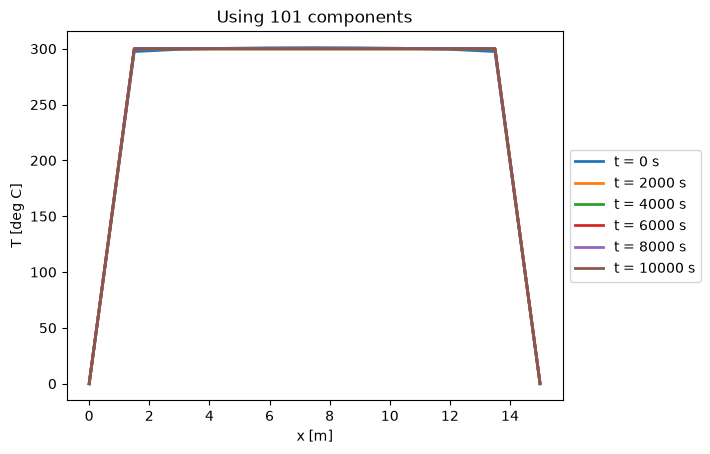

In [146]:
# Initialize Figure
plt.figure()

# Number of plots/interested points of time
Np = 5                                  
t_index = np.arange(0, Nt, Nt//Np) 


# Plot the state at different points of time
for pp in range(len(t_index)):
    plt.plot(xx, T_tot[:, t_index[pp]], linewidth=2, label = f't = {t[t_index[pp]]:.0f} s')


# Add Title, Labels and Legends
#plt.title(f"Temperature States at Different Moments of Time when n = {N_sum}")
plt.title(f"Using {N_sum} components")
plt.xlabel('x [m]')
plt.ylabel('T [deg C]')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5));

### 2. Different components of Temperature solution at different time moments 

C:\Users\candi\AppData\Local\Temp\ipykernel_58124\2978775746.py:28: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout();


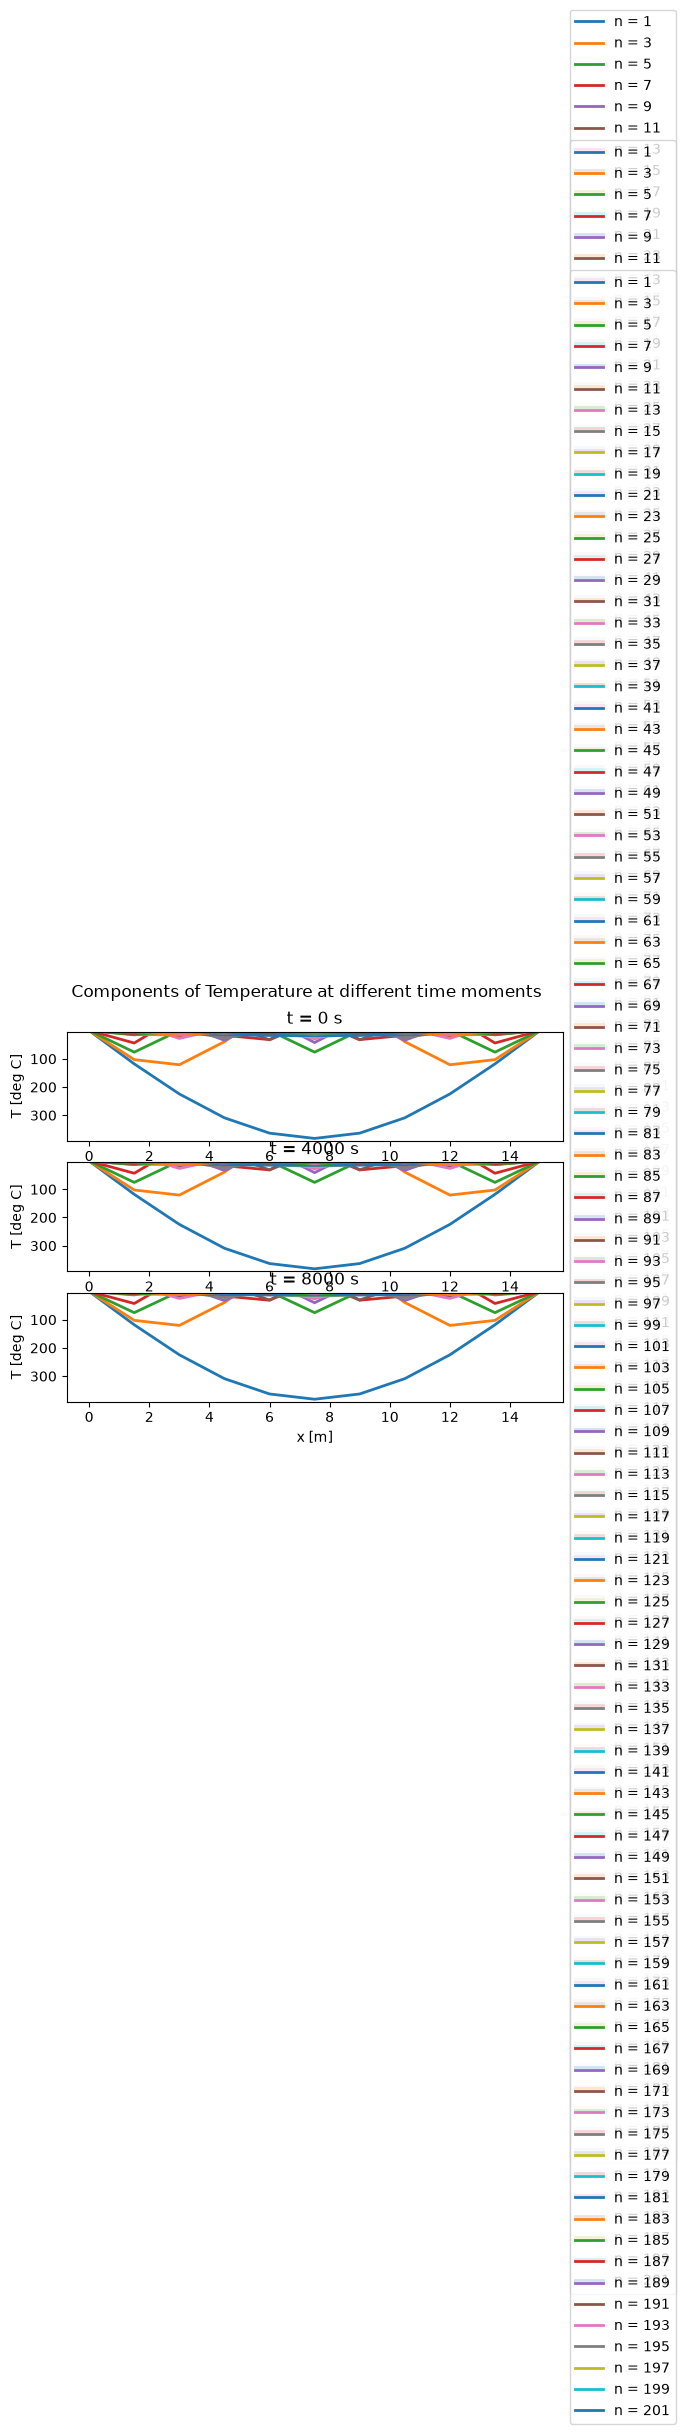

In [147]:
# Initialize Figure
plt.figure()

# Number of Sub Plots
N_fig = 3

t_index= np.arange(0, Nt, Nt//N_fig)

for subFig in range(1, N_fig+1):
    plt.subplot(N_fig,1,subFig)

    Np = N_sum
    N_sum_index= np.arange(0, N_sum, N_sum//Np)

    for pp in range(len(N_sum_index)):
        plt.plot(xx, T[N_sum_index[pp],:,t_index[subFig-1]], label = f"n = {(2*N_sum_index[pp]+1)}", linewidth = 2)
        plt.ylim(T0*1.3, 5)


    plt.title(f"t = {t[t_index[subFig - 1]]:.0f} s")
    plt.ylabel('T [deg C]')   
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.suptitle('Components of Temperature at different time moments')
plt.xlabel('x [m]')

# Automatically adjust the spacing to avoid overlap between titles and plots
plt.tight_layout();

## Only Relevant for Assignment 4
The next few code block are relevant for Assignment 4 for calculating the displacement

Given the second equation from the coupled set of equations for Soil consolidation:

\begin{aligned}
    \frac{\partial \varepsilon_x}{\partial x} = m_v \frac{\partial p_e}{\partial x}
\end{aligned}

We can integrate it w.r.t. $dx$ to get: 
\begin{aligned}
    \Delta \varepsilon_x = m_v \Delta p_e
\end{aligned}

Displacement is calculated from the contribution of strain for each element along the length:
\begin{aligned}
    disp(t) = \sum_{i =1}^{N_x - 1}{\Delta \varepsilon_{x, i} dx}
\end{aligned}

In [148]:
print("L =", L, " dx =", dx, " Nx =", Nx)
print("covered length (Nx-1)*dx =", (Nx-1)*dx, " (should be 15)")
print("tmax =", tmax, " Nt =", Nt)
print("T0 =", T0, " alpha =", alpha)
print("pore pressure at end, max over x:", T_tot[:, -1].max(), " (should be ~0)")
print("pore pressure at start, mid-column:", T_tot[Nx//2, 0], " (should be ~300)")

L = 15  dx = 1.5  Nx = 11
covered length (Nx-1)*dx = 15.0  (should be 15)
tmax = 10000  Nt = 6
T0 = 300  alpha = 2e-06
pore pressure at end, max over x: 300.0000000000001  (should be ~0)
pore pressure at start, mid-column: 300.9454517411621  (should be ~300)


In [149]:
mv = 0.0005     # 1/kPa
p = T0

displ = np.zeros(Nt)

# Calculation of Displacement
for jj in np.arange(0, Nt):
    for mm in np.arange(1, Nx):
        displ[jj] += mv * (p - T_tot[mm, jj]) * dx


# Displacment Calculated from Code and Formula
displ_code = displ[-1]
displ_formula = p * mv * L                 # Enter the formula used for Question 15

print(f"Settlement from code: \t\t{displ_code:.4f} m")
print(f"Settlement from formula: \t{displ_formula:.4f} m")

Settlement from code: 		0.2250 m
Settlement from formula: 	2.2500 m


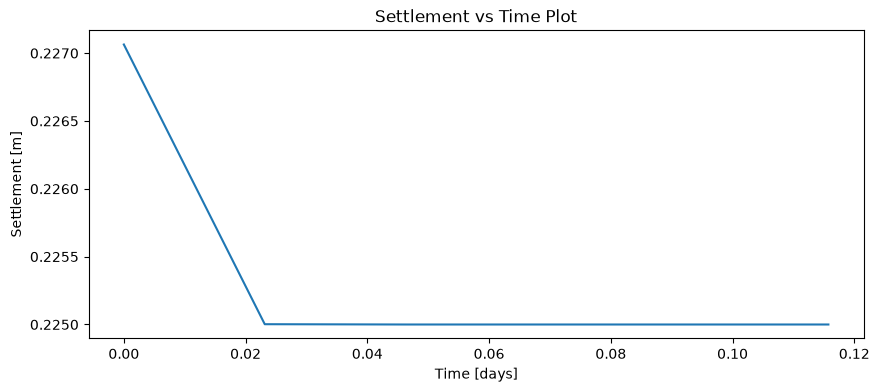

In [150]:
# Visualization of Settlement vs Time
plt.figure(figsize = (10, 4))
plt.plot(t/(24*60*60), displ)
plt.title("Settlement vs Time Plot")
plt.xlabel("Time [days]")
plt.ylabel("Settlement [m]");

## Time Taken for x% of maximum displacement

In [ ]:
max_displ = displ[-1]

disp_per = 50            # [%]

time_taken = 0

# Search for the first instance of displacement exceeding the specified %
for jj in np.arange(0, Nt):
    if displ[jj] >= (disp_per/100) * max_displ:
        time_taken = t[jj]     # Time vector is t
        break
    
print(f"Time taken for {disp_per}% of max displacement is {time_taken:.2e} s or {time_taken/(24*60*60):.1f} days")

Time taken for 50% of max displacement is 0.00e+00 s or 0.0 days
